# Demo 1 — Localizing the goal heads

**Question.** When the model starts writing a predicate (`return ...`), the code alone often does not determine what
comes next. Two different predicates can share the same opening tokens. Somewhere inside the model there must be a
signal that says *which* predicate it is implementing, i.e. its current goal. Which components carry that signal?

**Idea (cross-language interchange).** Take a **source** prompt that asks for predicate *A* in **C++** and a
**destination** prompt that asks for a different predicate *B* in **Python**, stopped at a *pivot*: a shared prefix
after which *A*'s and *B*'s Python implementations diverge. If we copy the right attention heads' outputs from the C++
run into the Python run, the Python run should continue as *A* would (the **target**). Only the *goal* can transfer:
the source is in another language and has no Python prefix, so token identity and syntax cannot carry over.

**Paper.** §3.1 "Localizing goal heads" (`Text/03_what.tex`, `fig:localization`) and App. "Localizing Goal Heads"
(`Text/Appendix/attn_head_localization.tex`).

**What you'll see.**
1. One oracle-mined pivot instance: the source, destination and target prompts, and their next-token distributions.
2. The intervention: patch the 122 goal heads' o_proj inputs from the C++ source into the Python destination at the
   last token, and watch the next-token distribution move to the target.
3. The 122 goal heads as a layer × head map from the trained mask (CPU, no training here).
4. Random-head controls on the same example, and the same comparison on a sample of instances.

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

**The setup** (schematics from the lab talk):

![Localizing goal heads: transplant every head's output from the C++ source run into the Python destination run at the pivot, and learn which heads carry the sub-goal (§3.1, App. C).](figures/01_localize_goal_heads.png)

*Localizing goal heads: transplant every head's output from the C++ source run into the Python destination run at the pivot, and learn which heads carry the sub-goal (§3.1, App. C).*

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.disable_progress_bars()

repo root: /disk/u/arnab/Codes/Projects/goals


## Config
**Why this example.** Source = `is_palindrome` in C++, destination = `is_upper` in Python, pivot prefix `s == s`. The two Python implementations share `return s == s` and then split: `s == s.upper()` versus `s == s[::-1]`. The divergence is readable by eye, and nothing in the destination prompt says "palindrome". We chose it in a pre-scan of 135 evenly spaced pivot instances (every 12th). In that scan the goal heads flipped the top-1 to the target on 106 of 135, against 1 of 135 for each random control, and this pair (with the wrapper prefix `False or s == s`) went from p(target) = 0.000 to 1.000 while both controls stayed at 0.000. Here we use the plain `s == s` variant of the same pair.

In [2]:
CUDA        = '7'                                   # one free 80 GB GPU
MODEL       = 'Qwen/Qwen2.5-Coder-32B-Instruct'
HEAD_SET    = 'head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json'          # 122 goal heads
CONTROL_SET = 'head_sets/Qwen2.5-Coder-32B-Instruct/control/control122__laterhalf.json'          # 122 random non-goal heads (layers >= 32)
MASK_PATH   = 'results/localization/Qwen2.5-Coder-32B-Instruct/lam20/head_mask.pt'               # trained lambda=20 mask
SOURCE_PRED = 'is_palindrome'          # C++ source predicate  (A)
DEST_PRED   = 'is_upper'          # Python destination predicate (B)
PIVOT_PREFIX = 's == s'      # shared prefix after `return `
THR         = 0.9                                   # mask threshold used for the exported head set
N_SWEEP     = 60                                    # instances for the aggregate check (section 5)
SEED        = 0

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA

## Load the model and the head sets

In [3]:
import json, random, torch
import numpy as np, matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.markup import escape

from src.models import ModelandTokenizer
from src.utils import experiment_utils
from src.goals.head_sets import load_json_heads
from src.goals.head_loc_data import HeadLocDataset
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt, get_next_token_probs_batch
from src.goals.head_loc_attn import HeadMask, get_o_proj_inputs_batch, forward_with_src_replacement
from src.tokens import prepare_input

console = Console(width=130, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
goal_heads = load_json_heads(HEAD_SET, mt.n_layer, mt.n_heads)
control_heads = load_json_heads(CONTROL_SET, mt.n_layer, mt.n_heads)
# a second, band-matched control: random non-goal heads drawn from the goal heads' own layer band (28-55)
_rng = random.Random(SEED)
_gs = set(goal_heads)
_pool = [(l, h) for l in range(28, 56) for h in range(mt.n_heads) if (l, h) not in _gs]
band_random_heads = sorted(_rng.sample(_pool, len(goal_heads)))
print(f'{MODEL}: {mt.n_layer} layers x {mt.n_heads} heads (head_dim {mt.head_dim})')
print(f'goal heads {len(goal_heads)} | control122 {len(control_heads)} | band-matched random {len(band_random_heads)}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Qwen/Qwen2.5-Coder-32B-Instruct: 64 layers x 40 heads (head_dim 128)
goal heads 122 | control122 122 | band-matched random 122


## 1. A pivot instance
The data lives in `data/head_loc/`: `predicates/*.json` holds one single-predicate sample per file (Python and C++
signatures stopped at `return`, a one-line docstring, unit tests). `pairs/Qwen2.5-Coder-32B-Instruct.json` holds the
**oracle-verified predicate pairs** and their **pivot instances**. `scripts/mine_pivot_instances.py` mined these: an LLM
oracle proposes shared prefixes for two predicates, and a prefix is kept only if (a) the model's greedy completions of
both predicates from `return <prefix>` pass their unit tests, and (b) the two predicates' top next tokens at the prefix
differ.

Three prompts per instance (built exactly as in mask training, `include_docstring=True`):
- **source**: predicate *A* in C++, ending at `return ` (no prefix);
- **destination**: predicate *B* in Python, ending at `return <prefix>`;
- **target**: predicate *A* in Python, ending at `return <prefix>`. It is never patched; it only defines what success looks like.

In [4]:
ds = HeadLocDataset.load(model_name=MODEL.split('/')[-1])
print(f'{len(ds.samples)} predicates | {len(ds.pairs)} oracle-verified pairs | {len(ds.pivot_instances)} pivot instances')

pair, pi = next((p, q) for p, q in ds.pivot_instances
                if p.source_predicate == SOURCE_PRED and p.destination_predicate == DEST_PRED and q.pivot_prefix == PIVOT_PREFIX)
src_s, dst_s = ds.get_sample(pair.source_predicate), ds.get_sample(pair.destination_predicate)
src_prompt  = build_cpp_prompt(mt, src_s, include_docstring=True)
dest_prompt = build_python_prompt(mt, dst_s, pivot_prefix=pi.pivot_prefix, include_docstring=True)
targ_prompt = build_python_prompt(mt, src_s, pivot_prefix=pi.pivot_prefix, include_docstring=True)

def assistant_part(p):  # the code the model is continuing (drop system/user turns for display)
    return p.split('<|im_start|>assistant\n')[-1]

for name, p, col in [('SOURCE (A, C++)', src_prompt, 'cyan'), ('DESTINATION (B, Python)', dest_prompt, 'yellow'),
                     ('TARGET (A, Python)', targ_prompt, 'green')]:
    console.rule(f'[{col}]{name}')
    console.print(f'[{col}]' + escape(assistant_part(p)) + f'[/{col}]' + '[reverse]▌[/reverse]')
console.rule()
print(f'pivot prefix: {pi.pivot_prefix!r} | mined top tokens: dest {pi.dest_top_token!r} vs target {pi.target_top_token!r}')

21 predicates | 110 oracle-verified pairs | 1613 pivot instances


──────────────────────────────────────────────────────── SOURCE (A, C++) ─────────────────────────────────────────────────────────

<code>
// Return True if s reads the same forwards and backwards.
bool isPalindrome(string s) { return ▌

──────────────────────────────────────────────────── DESTINATION (B, Python) ─────────────────────────────────────────────────────

<code>
def is_upper(s: str) -> bool:
    """Return True if all alphabetic characters in s are uppercase."""
    return s == s▌

─────────────────────────────────────────────────────── TARGET (A, Python) ───────────────────────────────────────────────────────

<code>
def is_palindrome(s: str) -> bool:
    """Return True if s reads the same forwards and backwards."""
    return s == s▌

──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

pivot prefix: 's == s' | mined top tokens: dest '.upper' vs target '[::-'


## 2. Destination vs. target: where the two predicates diverge
At the pivot the destination and target prompts have the same Python prefix and differ only in the predicate requested.
Their next-token distributions should be nearly disjoint.

In [5]:
P = get_next_token_probs_batch(mt, [dest_prompt, targ_prompt])   # (2, vocab)
dest_id, targ_id = P[0].argmax().item(), P[1].argmax().item()
tok = lambda i: repr(mt.tokenizer.decode([i]))

def topk_str(p, k=5):
    v, i = p.topk(k)
    return '  '.join(f'{tok(j)} {x:.2f}' for x, j in zip(v.tolist(), i.tolist()))

t = Table(title='next-token distribution at the pivot (clean runs)')
t.add_column('run'); t.add_column('top-5')
t.add_row('destination (B)', topk_str(P[0])); t.add_row('target (A)', topk_str(P[1]))
console.print(t)
print(f'dest top {tok(dest_id)} | target top {tok(targ_id)} | p_dest(target tok) = {P[0, targ_id]:.4f}')

                         next-token distribution at the pivot (clean runs)                          
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ run             ┃ top-5                                                                          ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ destination (B) │ '.upper' 1.00  '.toUpperCase' 0.00  ' upper' 0.00  '_upper' 0.00  'upper' 0.00 │
│ target (A)      │ '[::-' 1.00  '[' 0.00  '[-' 0.00  '[:' 0.00  '.reverse' 0.00                   │
└─────────────────┴────────────────────────────────────────────────────────────────────────────────┘

dest top '.upper' | target top '[::-' | p_dest(target tok) = 0.0000


## 3. The intervention: transplant the goal heads from C++ into Python
For each selected head $[\ell, j]$, the input to `o_proj` at the destination's **last token** (that head's slice, i.e.
its OV output before the output projection) is replaced by the same head's value at the **last token of the C++
source**:

$$a^{\ell j}_{-1} \leftarrow m^{\ell j}\, a^{\ell j}_\mathrm{src} + (1-m^{\ell j})\, a^{\ell j}_{-1}, \qquad m^{\ell j}\in\{0,1\}.$$

Training learns a continuous $m$ that minimises $\mathrm{KL}(p_\mathrm{patched}\,\|\,p_\mathrm{target})$ plus
$\lambda\cdot\mathrm{mean}(m)$. Here we only *apply* the binarized result (the 122 goal heads, $m=1$). Patches cascade:
layer $\ell$'s patch changes what later layers compute. `forward_with_src_replacement` is the exact hook used during
training (`src/goals/head_loc_attn.py`).

In [6]:
LAYERS = list(range(mt.n_layer))

def binary_mask(heads):
    m = HeadMask(n_layers_tested=mt.n_layer, n_heads=mt.n_heads)
    m.values.data.zero_()
    for l, h in heads:
        m.values.data[l, h] = 1.0
    return m

def patched_probs(src_prompt, dest_prompt, heads):
    so = get_o_proj_inputs_batch(mt, [src_prompt], LAYERS)            # {layer: (1, n_heads*head_dim)} at the last token
    src_vals = torch.stack([so[l][0] for l in LAYERS])               # (n_layers, n_heads*head_dim)
    logits = forward_with_src_replacement(mt, prepare_input([dest_prompt], tokenizer=mt), src_vals, binary_mask(heads), LAYERS)
    return torch.softmax(logits.float(), -1).cpu()

p_goal = patched_probs(src_prompt, dest_prompt, goal_heads)

t = Table(title='before / after patching the 122 goal heads', show_lines=True)
t.add_column('run'); t.add_column('top-1'); t.add_column(f'p({tok(targ_id)}) target', justify='right')
t.add_column(f'p({tok(dest_id)}) dest', justify='right'); t.add_column('top-5')
for name, p in [('destination, clean', P[0]), ('destination + goal heads from C++', p_goal), ('target, clean (reference)', P[1])]:
    t.add_row(name, tok(p.argmax().item()), f'{p[targ_id]:.3f}', f'{p[dest_id]:.3f}', topk_str(p))
console.print(t)

                                            before / after patching the 122 goal heads                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ run                               ┃ top-1    ┃ p('[::-') target ┃ p('.upper') dest ┃ top-5                                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ destination, clean                │ '.upper' │            0.000 │            1.000 │ '.upper' 1.00  '.toUpperCase' 0.00  '     │
│                                   │          │                  │                  │ upper' 0.00  '_upper' 0.00  'upper' 0.00  │
├───────────────────────────────────┼──────────┼──────────────────┼──────────────────┼───────────────────────────────────────────┤
│ destination + goal heads from C++ │ '[::-'   │            1.000 │            0.000 │ '[::-' 1.00  '.lower' 0.00  '.upper' 0.00 │
│                                   │          │                  │                  │ '[' 0.00  '[:' 0.00                       │
├───────────────────────────────────┼──────────┼──────────────────┼──────────────────┼───────────────────────────────────────────┤
│ target, clean (reference)         │ '[::-'   │            1.000 │            0.000 │ '[::-' 1.00  '[' 0.00  '[-' 0.00  '[:'    │
│                                   │          │                  │                  │ 0.00  '.reverse' 0.00                     │
└───────────────────────────────────┴──────────┴──────────────────┴──────────────────┴───────────────────────────────────────────┘

Copying 122 of the model's 2,560 heads at a **single token**, from a run in a *different language*, makes the Python run
continue as predicate *A* would. The source run never saw the Python prefix, so what moved across can only be *which
predicate to implement*, not *how to write it in Python*.

## 4. The 122 goal heads
The mask `results/localization/Qwen2.5-Coder-32B-Instruct/lam20/head_mask.pt` (1,423 pivot instances per its stored config, fewer
than the pairs file printed above now holds; 50 epochs,
$\lambda=20$, per-epoch augmentation: variable renames, type-hint toggles, other source languages) is loaded on CPU.
The exported head set keeps heads with mask value > 0.9 in layers 25–55. The plot reuses the figure code of
`notebooks/fig_n_table_generators/head_localization.ipynb` (the right panel of `fig:localization`).

config: {'model': 'Qwen/Qwen2.5-Coder-32B-Instruct', 'n_instances': 1423, 'n_epochs': 50, 'lr': 0.01, 'lambda_sparse': 20.0, 'batch_size': 64, 'precompute': False, 'augment': True, 'augment_seed': 123456, 'approach': 'src_replacement'}
122 heads with mask > 0.9 in layers 25-55 == head-set json: True; layers spanned 28-55


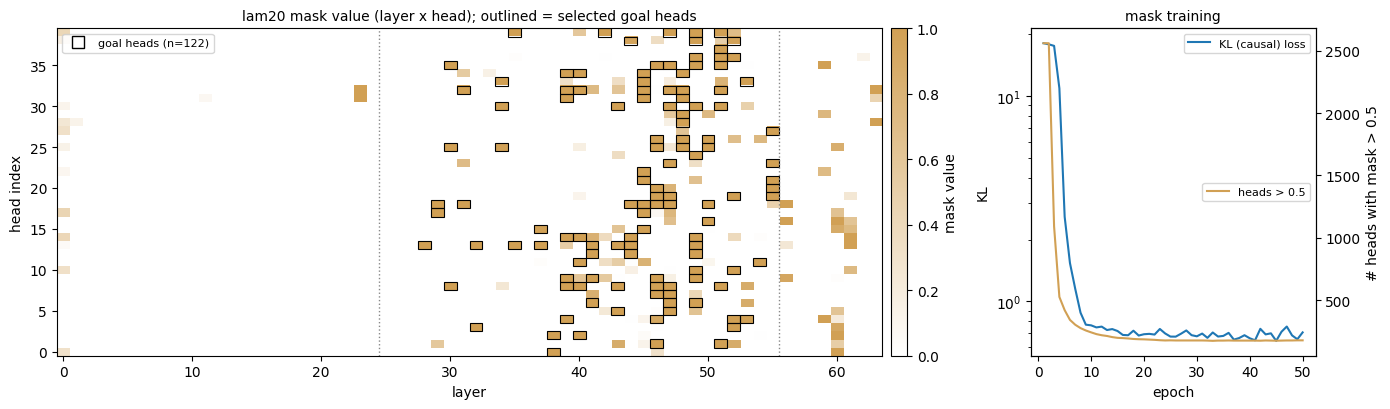

val recall@1..5 at the last epoch: [0.746, 0.884, 0.919, 0.933, 0.937]


In [7]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
ck = torch.load(MASK_PATH, map_location='cpu', weights_only=False)
mv = ck['mask_values'].numpy(); layers = [int(x) for x in ck['layers']]
GRID = np.full((mt.n_layer, mv.shape[1]), np.nan)
for i, l in enumerate(layers): GRID[l] = mv[i]
_m = np.nan_to_num(GRID).copy(); _m[:25] = 0; _m[56:] = 0
SEL = sorted((int(l), int(h)) for l, h in np.argwhere(_m > THR))
assert SEL == sorted(goal_heads), 'mask threshold does not reproduce the exported head set'
print(f"config: {ck['config']}")
print(f'{len(SEL)} heads with mask > {THR} in layers 25-55 == head-set json: {SEL == sorted(goal_heads)}; '
      f'layers spanned {SEL[0][0]}-{SEL[-1][0]}')

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[3, 1]))
cmap = LinearSegmentedColormap.from_list('goal', ['white', '#d1a054'], N=256); cmap.set_bad('#EFEFEF')
im = ax.imshow(np.ma.masked_invalid(GRID.T), cmap=cmap, aspect='auto', vmin=0, vmax=1, interpolation='nearest', origin='lower')
for l, h in SEL:
    ax.add_patch(Rectangle((l - 0.5, h - 0.5), 1, 1, fill=False, edgecolor='black', linewidth=0.8))
for xb in (24.5, 55.5): ax.axvline(xb, color='#888', ls=':', lw=1)
ax.plot([], [], marker='s', ls='none', mfc='none', mec='black', markersize=8, label=f'goal heads (n={len(SEL)})')
ax.set_xlabel('layer'); ax.set_ylabel('head index'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('lam20 mask value (layer x head); outlined = selected goal heads', fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).set_label('mask value')
h = ck['history']
ax2.plot(range(1, len(h['loss_causal']) + 1), h['loss_causal'], label='KL (causal) loss')
ax2.set_xlabel('epoch'); ax2.set_ylabel('KL'); ax2.set_yscale('log')
ax3 = ax2.twinx(); ax3.plot(range(1, len(h['n_active']) + 1), h['n_active'], color='#d1a054', label='heads > 0.5')
ax3.set_ylabel('# heads with mask > 0.5'); ax2.set_title('mask training', fontsize=10)
ax2.legend(loc='upper right', fontsize=8); ax3.legend(loc='center right', fontsize=8)
fig.tight_layout(); plt.show()
print('val recall@1..5 at the last epoch:', [round(x, 3) for x in h['val_recall'][-1]])

## 5. Control: is it just "patch any 122 heads"?
Same example, same patch, two random head sets of the same size:
- `control122__laterhalf.json`: the repo's random non-goal control (122 heads from layers ≥ 32, seed 123);
- a band-matched draw: 122 random non-goal heads from layers 28–55, the goal heads' own band.

In [8]:
p_ctrl = patched_probs(src_prompt, dest_prompt, control_heads)
p_rand = patched_probs(src_prompt, dest_prompt, band_random_heads)
t = Table(title='same example, different head sets', show_lines=True)
t.add_column('run'); t.add_column('top-1'); t.add_column(f'p({tok(targ_id)}) target', justify='right')
t.add_column(f'p({tok(dest_id)}) dest', justify='right'); t.add_column('top-5')
for name, p in [('destination, clean', P[0]), ('+ 122 goal heads', p_goal), ('+ control122 (random, L>=32)', p_ctrl),
                ('+ 122 random heads, L28-55', p_rand), ('target, clean (reference)', P[1])]:
    t.add_row(name, tok(p.argmax().item()), f'{p[targ_id]:.3f}', f'{p[dest_id]:.3f}', topk_str(p))
console.print(t)

                                                same example, different head sets                                                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ run                          ┃ top-1    ┃ p('[::-') target ┃ p('.upper') dest ┃ top-5                                          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ destination, clean           │ '.upper' │            0.000 │            1.000 │ '.upper' 1.00  '.toUpperCase' 0.00  ' upper'   │
│                              │          │                  │                  │ 0.00  '_upper' 0.00  'upper' 0.00              │
├──────────────────────────────┼──────────┼──────────────────┼──────────────────┼────────────────────────────────────────────────┤
│ + 122 goal heads             │ '[::-'   │            1.000 │            0.000 │ '[::-' 1.00  '.lower' 0.00  '.upper' 0.00  '[' │
│                              │          │                  │                  │ 0.00  '[:' 0.00                                │
├──────────────────────────────┼──────────┼──────────────────┼──────────────────┼────────────────────────────────────────────────┤
│ + control122 (random, L>=32) │ '.upper' │            0.000 │            1.000 │ '.upper' 1.00  '.toUpperCase' 0.00  ' upper'   │
│                              │          │                  │                  │ 0.00  '_upper' 0.00  'upper' 0.00              │
├──────────────────────────────┼──────────┼──────────────────┼──────────────────┼────────────────────────────────────────────────┤
│ + 122 random heads, L28-55   │ '.upper' │            0.000 │            1.000 │ '.upper' 1.00  '.toUpperCase' 0.00  ' upper'   │
│                              │          │                  │                  │ 0.00  '_upper' 0.00  'upper' 0.00              │
├──────────────────────────────┼──────────┼──────────────────┼──────────────────┼────────────────────────────────────────────────┤
│ target, clean (reference)    │ '[::-'   │            1.000 │            0.000 │ '[::-' 1.00  '[' 0.00  '[-' 0.00  '[:' 0.00    │
│                              │          │                  │                  │ '.reverse' 0.00                                │
└──────────────────────────────┴──────────┴──────────────────┴──────────────────┴────────────────────────────────────────────────┘

### Beyond one example
One instance can be lucky. Below, the same three head sets on a fixed, evenly spaced sample of the pivot instances.
Success = the patched top-1 equals the target's top-1. These instances were used to *train* the mask, so this is a
sanity check of the exported head set, not a held-out score. The training run's held-out recall@1 is printed above.

In [9]:
from tqdm.auto import tqdm
pis = ds.pivot_instances
sample = [pis[i] for i in np.linspace(0, len(pis) - 1, N_SWEEP).astype(int)]
hits = {'goal heads': 0, 'control122': 0, 'random L28-55': 0}
for pr, q in tqdm(sample):
    a, b = ds.get_sample(pr.source_predicate), ds.get_sample(pr.destination_predicate)
    sp = build_cpp_prompt(mt, a, include_docstring=True)
    dp = build_python_prompt(mt, b, pivot_prefix=q.pivot_prefix, include_docstring=True)
    tp = build_python_prompt(mt, a, pivot_prefix=q.pivot_prefix, include_docstring=True)
    tgt = get_next_token_probs_batch(mt, [tp])[0].argmax().item()
    for k, hs in [('goal heads', goal_heads), ('control122', control_heads), ('random L28-55', band_random_heads)]:
        hits[k] += int(patched_probs(sp, dp, hs).argmax().item() == tgt)
t = Table(title=f'patched top-1 == target top-1 on {len(sample)} pivot instances')
t.add_column('head set (122 heads each)'); t.add_column('success', justify='right')
for k, v in hits.items(): t.add_row(k, f'{v}/{len(sample)} = {v / len(sample):.0%}')
console.print(t)

 patched top-1 == target top-1 on 60 pivot 
                 instances                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ head set (122 heads each) ┃     success ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ goal heads                │ 50/60 = 83% │
│ control122                │   0/60 = 0% │
│ random L28-55             │   2/60 = 3% │
└───────────────────────────┴─────────────┘

## Where this goes in the paper / how to reproduce at scale
- **Paper**: §3.1 and `fig:localization`: "122 heads distributed in layers 28–55 of the 64-layer
  Qwen-2.5-Coder-32B-Instruct". The right panel is `notebooks/fig_n_table_generators/head_localization.ipynb`.
- **Pipeline** (no training in this notebook):
  1. `python scripts/mine_pivot_instances.py --model-key Qwen/Qwen2.5-Coder-32B-Instruct`: oracle pair verification
     (`data/head_loc/global_pairs.json`) and pivot mining with unit-test and divergence gates
     (`src/goals/head_loc_oracle.py`) -> `data/head_loc/pairs/<model>.json`.
  2. `python -m scripts.train_head_mask`: the defaults are the paper's lam20 run (50 epochs, batch 64, lr 0.01, λ 20,
     augmentation on) -> `results/localization/Qwen2.5-Coder-32B-Instruct/lam20/head_mask.pt`. Smoke:
     `--tag scratch_smoke --n-epochs 1`.
  3. `python scripts/data/export_head_sets.py` -> `head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json`.
- **Other models**: CLAUDE.md §3.2 lists the mask and head set of each model (Coder-14B: 88 heads, Qwen2.5-32B: 108,
  OLMo, Llama-70B).
- **Next**: Demo 2 (`02_goalscope.ipynb`) reads these heads out with GoalScope. The heads' write at a single token
  verbalizes the upcoming sub-goal.